In [1]:
# === Google Colab 自動環境セットアップ ===
# 本セルを実行すると、Google Colab 上で必要なリポジトリのクローン、
# 依存ライブラリのインストール、および共通シミュレーションモジュールの準備が自動的に行われます。
import os
import sys
import subprocess

if 'google.colab' in str(get_ipython()):
    print('Google Colab 環境を検出しました。環境をセットアップします...')
    repo_name = 'study-mikanos'
    if not os.path.exists(repo_name):
        subprocess.run(['git', 'clone', 'https://github.com/miyayudai/study-mikanos.git'], check=True)
    os.chdir(repo_name)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', '.'], check=True)
    print('Colab 環境のセットアップが完了しました！')
else:
    # ローカル環境のパス設定 (study-mikanos を最優先でロード)
    repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '5' else os.getcwd()
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print('ローカル環境で実行中です。ルートディレクトリ:', repo_root)


ローカル環境で実行中です。ルートディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 5.4 文字列描画とsprintf() (`String Rendering and sprintf`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/5/5.4_String_Rendering_and_sprintf.ipynb)

前節（5.3節）では、アスキーアートフォント定義 `hankaku.txt` を `makefont.py` で生バイナリ `hankaku.bin` へ変換し、GNU Binutils `objcopy` を用いて ELF64 オブジェクトファイル `hankaku.o` としてカーネルにリンクしました。これにより、ASCII コード 0x00〜0xFF の全文字をピクセル展開できる基盤が完成しました。

しかし、前節までの実装では `WriteAscii(writer, x, y, c, color)` による **「1文字単位の描画」** しか行えませんでした。OS が起動メッセージやメモリマップ情報、デバッグ値、エラーログを表示するためには、**「文字列の連続描画」** と **「数値の10進数・16進数への書式整形（フォーマット変換）」** が絶対に欠かせません。

本節では、以下の重要技術を完全に解明・実装します：
1. **`WriteString()` の実装**: 終端ヌル文字 (`'\0'`) 検出と 8 ドット等幅送り数理アルゴリズム
2. **Newlib（標準Cライブラリ）のリンク (`-lc`)**: Freestanding 環境における C 標準関数の統合
3. **システムコールスタブ `sbrk()` の必然性**: なぜ `sprintf()` がヒープ拡張システムコールを要求するのかのアーキテクチャ解明
4. **System V AMD64 ABI における可変長引数 (`<cstdarg>`) の数理**: レジスタ渡し（RDI〜R9, AL）とスタックフレーム (`va_list`) の完全モデル化


## 1. なぜ文字列描画と書式付き出力が必要なのか？（動機と課題）

### 1.1 単一文字描画 `WriteAscii()` の限界
5.3節（`osbook_day05c`）で文字 `'!'` から `'~'` を描画した際のコードを振り返ってみましょう：

```cpp
int i = 0;
for (char c = '!'; c <= '~'; ++c, ++i) {
    WriteAscii(*pixel_writer, 8 * i, 50, c, {0, 0, 0});
}
```

この方法では、`"Hello, world!"` のような一般的な文字列を出力したい場合でも、呼び出し側がいちいち文字配列の長さを数え、ループを書き、座標 `8 * i` を計算しなければなりません。
もしカーネルのあちこちでこのループを書くと、コードが肥大化するだけでなく、座標計算のミスやオフセットのずれといった初歩的バグが頻発します。

### 1.2 OSカーネルにおける数値の可視化課題
さらに深刻な問題が **「数値の可視化」** です。OS 開発では以下のような数値を画面に出力してデバッグすることが日常茶飯事です：
- CPU レジスタ値（`RIP`, `RSP`, `CR0`, `CR3` など）
- メモリアドレス（フレームバッファ先頭番地 `0x100000`、ページテーブル番地など）
- 実行カウンタやタイマ値、PCI ベンダー ID / デバイス ID

しかし、コンピュータの内部表現（2進数のビット列）を人間が読める ASCII 文字列（例: `"1 + 2 = 3"` や `"0x00100000"`）に変換するには、除算・剰余算による10進数展開や16進数ビットシフト処理が必要となります。
このフォーマット変換を安全かつ汎用的に行う標準関数が、C言語の `sprintf()` です。

### 1.3 本節の達成目標 (`osbook_day05d`)
本節では、MikanOS カーネルに以下の2行の描画処理を追加し、文字列と数値の画面出力を実現します：

```cpp
WriteString(*pixel_writer, 0, 66, "Hello, world!", {0, 0, 255}); // 青文字で文字列出力

char buf[128];
sprintf(buf, "1 + 2 = %d", 1 + 2);
WriteString(*pixel_writer, 0, 82, buf, {0, 0, 0});              // 黒文字で計算結果出力
```


## 2. 文字列描画 `WriteString()` の実装と 8 ドット等幅送り数理アルゴリズム

### 2.1 幾何モデルと座標変換式
文字列 $s$ が与えられたとき、$s$ は C 言語のヌル終端文字列（*Null-terminated string*）としてメモリ上に連続配置されています：

$$s = \langle c_0, c_1, c_2, \dots, c_{N-1}, \texttt{'\textbackslash 0'} \rangle$$

各文字グリフは幅 $W = 8$ ピクセル、高さ $H = 16$ ピクセルの等幅フォント（*Monospaced Font*）です。
文字列の描画開始座標を $(x, y)$ とすると、第 $i$ 番目の文字 $c_i$ の描画原点 $(x_i, y_i)$ は以下の線形等差数列で決定されます：

$$x_i = x + W \cdot i = x + 8 \cdot i$$
$$y_i = y$$

第 $i$ 文字のピクセル占有矩形（バウンディングボックス）は、半開区間として次のように定義されます：

$$\text{BBox}(c_i) = [x + 8i, \, x + 8(i + 1)) \times [y, \, y + 16)$$

文字列全体の総ピクセル幅 $W_{\text{total}}$ は文字数 $N$ に比例します：

$$W_{\text{total}} = 8 \cdot N \quad [\text{pixels}]$$

### 2.2 終端ヌル文字 `'\0'` の検出とポインタ走査
C言語の文字列ポインタ `const char* s` は配列インデックス `s[i]` でアクセスでき、`s[i] == '\0'`（ASCII コード 0）となるまでループを回します。

```cpp
void WriteString(PixelWriter& writer, int x, int y, const char* s, const PixelColor& color) {
    for (int i = 0; s[i] != '\0'; ++i) {
        WriteAscii(writer, x + 8 * i, y, s[i], color);
    }
}
```

ポインタ演算で書く場合は以下のようにも表現できます：
```cpp
for (int i = 0; *s != '\0'; ++s, ++i) {
    WriteAscii(writer, x + 8 * i, y, *s, color);
}
```
コンパイラ（LLVM/Clang）の最適化により、どちらの記法でも同一の効率的な機械語コード（レジスタインクリメントとポインタ走査）が生成されます。


In [2]:
# === WriteString() アルゴリズムの Python シミュレーション検証 ===
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '5' else os.getcwd()
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from common import StringRendererSim
import numpy as np

# 1. 座標計算の検証
sample_str = "Hello, world!"
positions = StringRendererSim.calculate_glyph_positions(x=0, y=66, s=sample_str)

print(f"文字列: '{sample_str}' (文字数: {len(sample_str)})")
print(f"総描画幅: {StringRendererSim.get_string_width(sample_str)} ピクセル")
print(f"バウンディングボックス: {StringRendererSim.get_string_bounding_box(0, 66, sample_str)}")
print("-" * 50)
print("先頭5文字の描画座標トレース:")
for p in positions[:5]:
    print(f"  Index {p['index']}: Char '{p['char']}' (ASCII 0x{p['ascii']:02X}) -> Origin: ({p['x']:3d}, {p['y']:2d}), BBox: {p['bbox']}")

# 2. フレームバッファへの描画シミュレーション
font_path = "hankaku.bin" if os.path.exists("hankaku.bin") else "5/hankaku.bin"
renderer = StringRendererSim(font_bin_path=font_path)
vram = np.ones((100, 200, 3), dtype=np.uint8) * 255  # 白背景
count = renderer.render_string(vram, x=0, y=66, s=sample_str, color=(0, 0, 255))
print(f"\nフレームバッファに正常描画された文字数: {count} 文字")


文字列: 'Hello, world!' (文字数: 13)
総描画幅: 104 ピクセル
バウンディングボックス: (0, 66, 104, 16)
--------------------------------------------------
先頭5文字の描画座標トレース:
  Index 0: Char 'H' (ASCII 0x48) -> Origin: (  0, 66), BBox: (0, 66, 8, 82)
  Index 1: Char 'e' (ASCII 0x65) -> Origin: (  8, 66), BBox: (8, 66, 16, 82)
  Index 2: Char 'l' (ASCII 0x6C) -> Origin: ( 16, 66), BBox: (16, 66, 24, 82)
  Index 3: Char 'l' (ASCII 0x6C) -> Origin: ( 24, 66), BBox: (24, 66, 32, 82)
  Index 4: Char 'o' (ASCII 0x6F) -> Origin: ( 32, 66), BBox: (32, 66, 40, 82)

フレームバッファに正常描画された文字数: 13 文字


## 3. 高解像度アーキテクチャ図版 (Figure 5.7) の徹底解剖

以下の図版（Figure 5.7）は、`WriteString()` における 8 ドット等幅送り数理アルゴリズムと、MikanOS `day05d` カーネルによる画面描画結果を完全可視化したものです：

- **Subplot 1 (上段)**: `"Hello"` を例にした各文字グリフの 8 ドット右送り ($x + 8 \cdot i$) と、終端ヌル文字 (`'\0'`) 検出によるループ脱出メカニズム。
- **Subplot 2 (下段)**: MikanOS `day05d` 実行画面の忠実なシミュレーション。$y=50$ の全 ASCII 文字列に加え、$y=66$ の青文字 `"Hello, world!"`、$y=82$ の黒文字 `"1 + 2 = 3"`（`sprintf` 出力）の配置関係を示します。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:19854: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


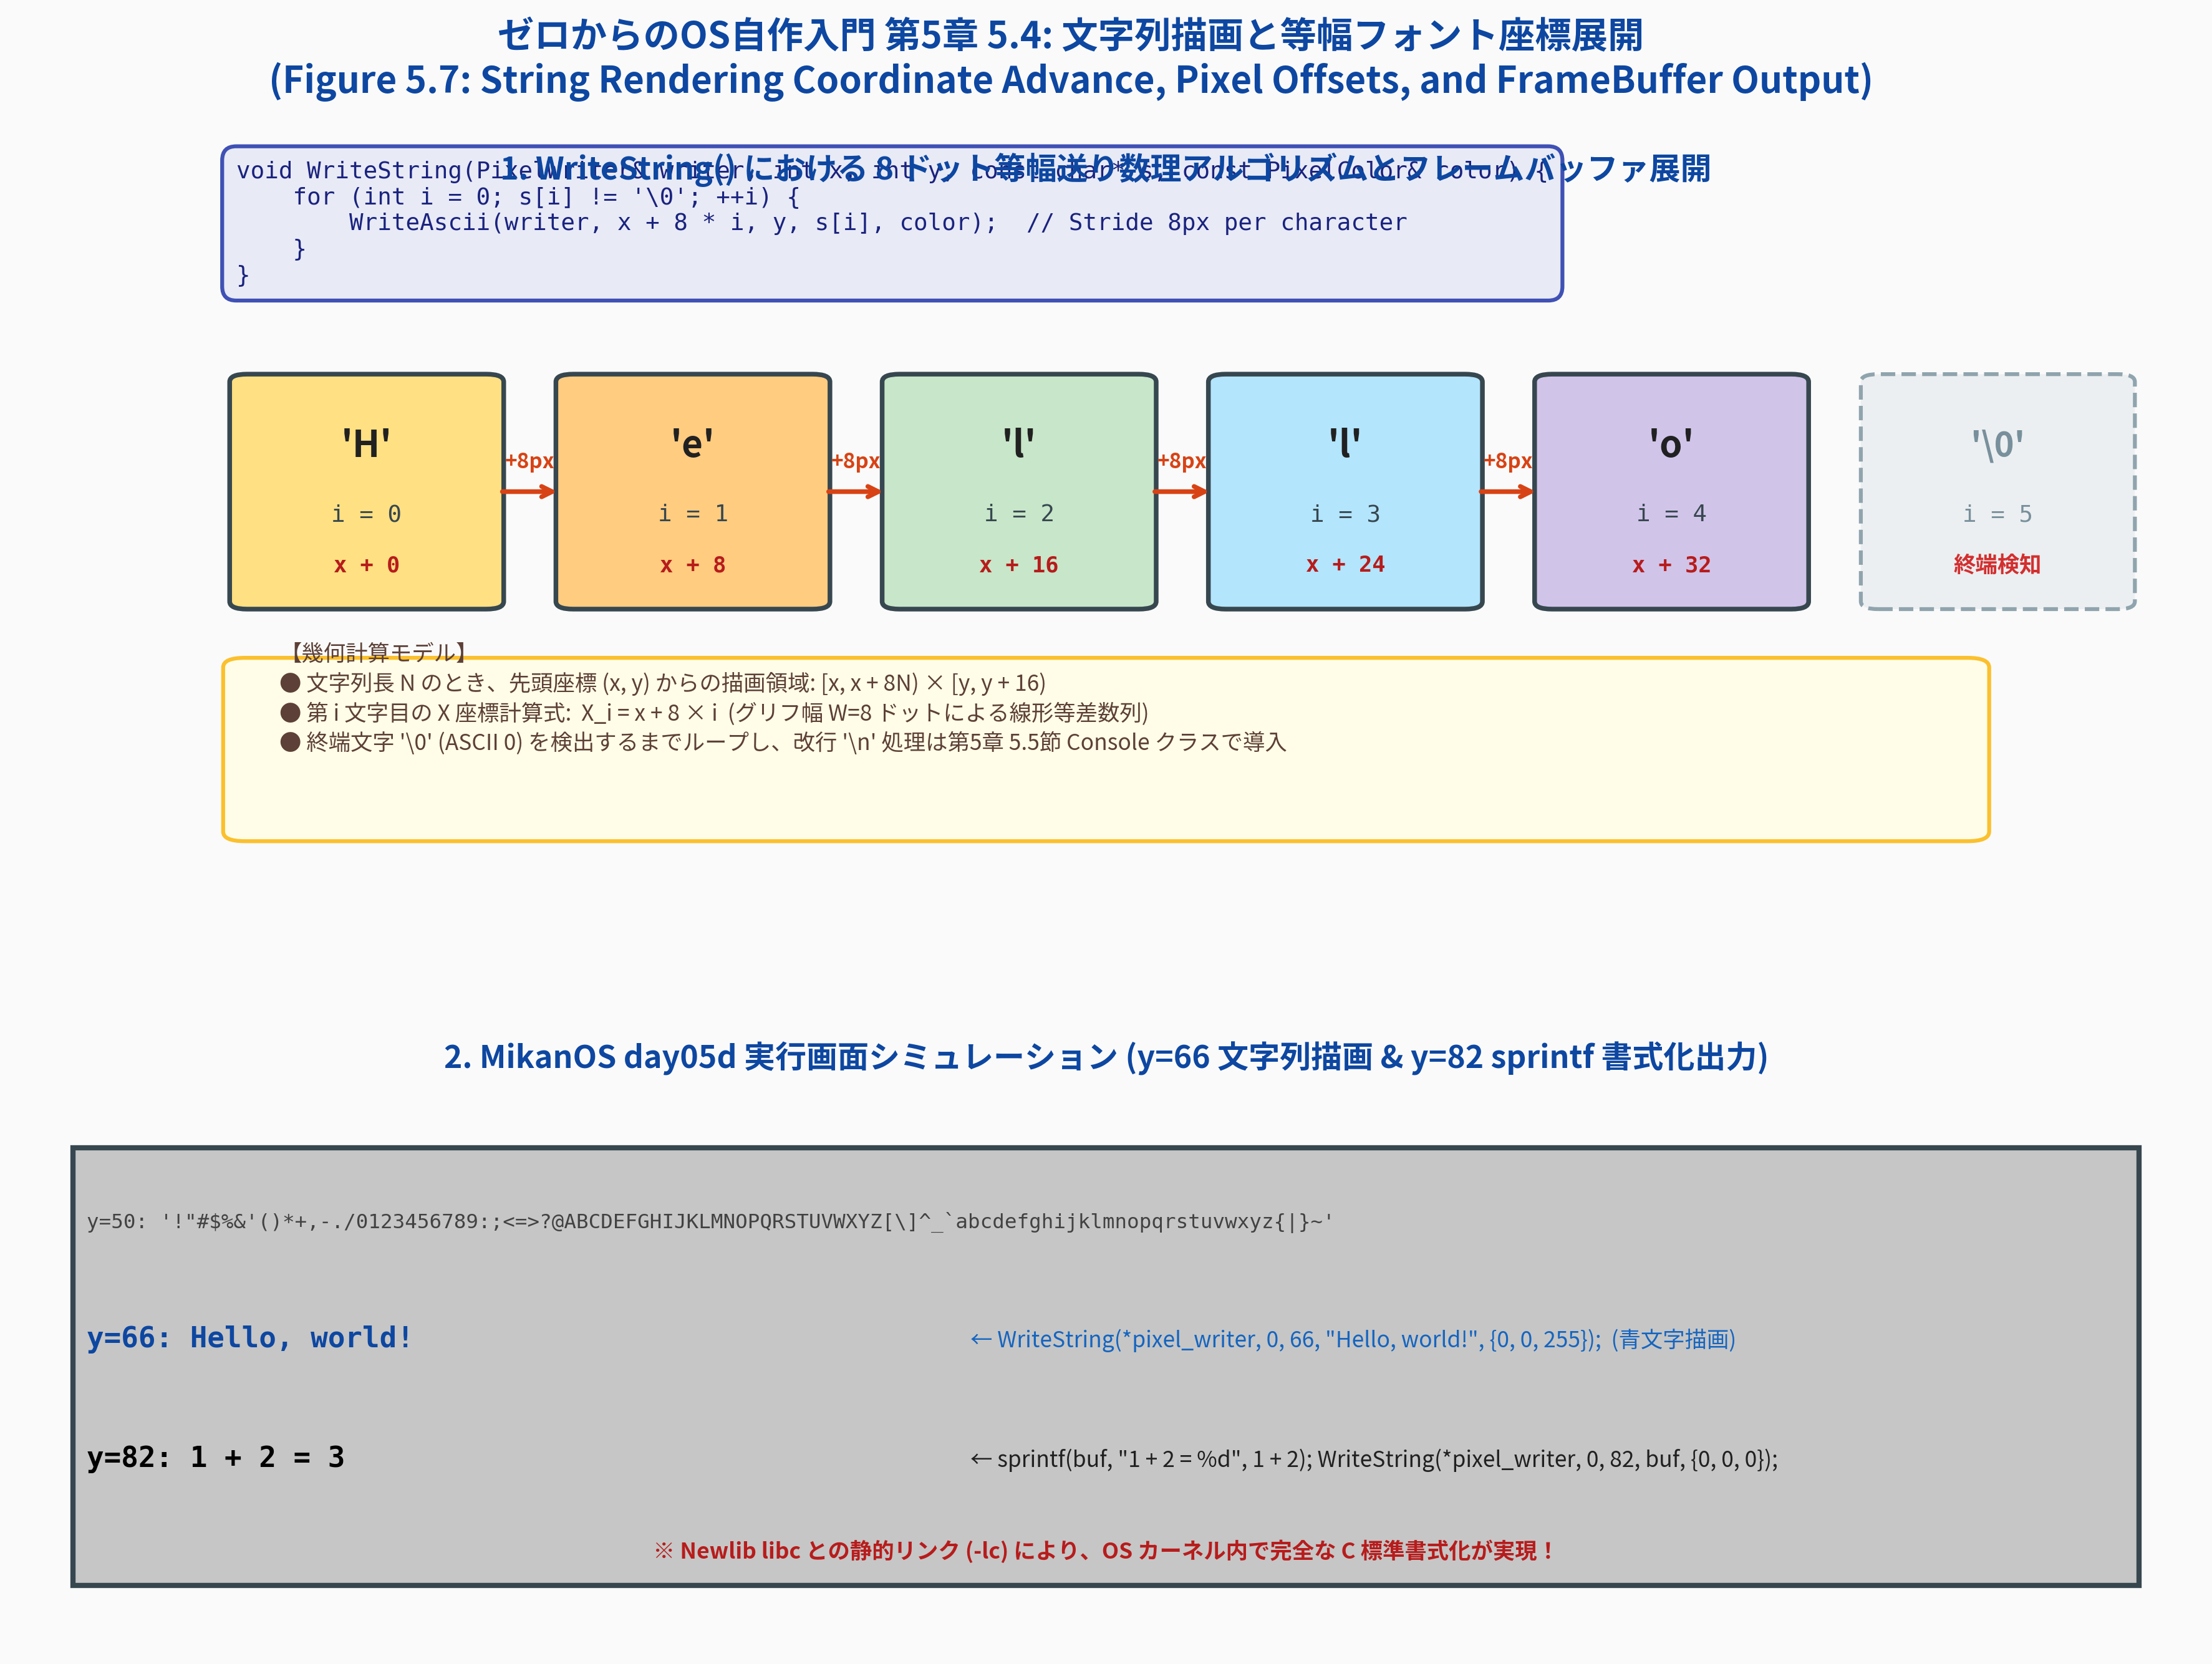

In [3]:
# === Figure 5.7: 文字列描画と等幅フォント座標展開の生成・表示 ===
import os
from common import plot_fig5_07_string_rendering_coordinate_advance
from IPython.display import Image, display

fig_dir = "result" if os.path.basename(os.getcwd()) == "5" else "5/result"
fig_path = os.path.join(fig_dir, "fig5_07_string_rendering_coordinate_advance.png")
plot_fig5_07_string_rendering_coordinate_advance(fig_path)
display(Image(filename=fig_path))


## 4. Newlib (標準Cライブラリ) のリンクとシステムコールスタブ `sbrk()`

### 4.1 Freestanding 環境と Hosted 環境の違い
C/C++ 言語の仕様（ISO C++ 規格）では、プログラムの実行環境を以下の2種類に厳密に分類しています：

| 環境種別 | コンパイラフラグ | 特徴と利用可能なライブラリ |
|---|---|---|
| **自立環境 (Freestanding)** | `-ffreestanding` | OS やローダが存在しないベアメタル環境。`<cstddef>`, `<cstdint>`, `<cstdarg>`, `<limits>` などのコンパイラ組み込みヘッダのみ利用可能。`printf`, `malloc`, `fopen` 等の標準関数は一切提供されない。 |
| **ホスト環境 (Hosted)** | デフォルト (通常) | Linux や Windows などの既存 OS 上で動く環境。ファイル入出力やメモリ管理を含むすべての C/C++ 標準ライブラリが完全に利用可能。 |

自作 OS カーネルは、それ自身が OS であるため必然的に **Freestanding 環境** で動作します。
そのため、`printf` や `sprintf` といった C 言語でおなじみの便利な関数は、通常は自作 OS の中には存在しません。

### 4.2 Newlib の役割とリンカフラグ `-lc`
しかし、書式化処理（10進数変換、浮動小数点変換、パディング処理など）をゼロからフルスクラッチで実装するのは膨大な労力がかかり、バグの温床になります。
そこで MikanOS では、組み込みシステム向けに設計された軽量かつ再入可能な標準 C ライブラリ **Newlib** を活用します。

カーネルの `Makefile` に以下の変更を加えます：
```makefile
kernel.elf: $(OBJS) Makefile
    ld.lld $(LDFLAGS) -o kernel.elf $(OBJS) -lc
```
`-lc` は、リンカに対して標準 C ライブラリ `libc.a` を静的リンクすることを指示します。
これにより、Newlib の `sprintf.o` や `vfprintf.o` が `kernel.elf` に組み込まれ、カーネル内で `sprintf()` が呼び出せるようになります。

### 4.3 なぜ `sprintf()` なのに `sbrk()` が要求されるのか？（依存関係の謎解き）
ところが、ただ `-lc` を追加してビルドすると、リンカは以下のような冷酷なエラーを出力します：

```text
ld.lld: error: undefined symbol: sbrk
>>> referenced by .../libc.a(lib_a-mallocr.o):(_malloc_r)
```

> [!IMPORTANT]
> **疑問**: `sprintf()` はメモリ上のバッファ（配列 `char buf[128]`）に文字列を書き込む関数であり、画面表示やディスク書き込みは行いません。なぜメモリ確保システムコール `sbrk()` が呼ばれるのでしょうか？

その理由は、Newlib の `sprintf` の内部実装にあります：
1. Newlib の `sprintf` は内部で汎用フォーマッタ `_vfprintf_r()` を呼び出します。
2. `_vfprintf_r()` は、非常に長い文字列や浮動小数点数（`%f` など）の変換を行う際に、スタックバッファのオーバーフローを防ぐため、必要に応じて動的メモリ確保（`malloc()`）を行うよう設計されています。
3. そして Newlib の `malloc()` は、OS のヒープ領域を拡大するために UNIX システムコール **`sbrk()`** を呼び出します。
4. MikanOS カーネルにはまだメモリ管理（ヒープ）が存在しないため、`sbrk()` のシンボルが見つからず、リンクエラーが発生するのです！

### 4.4 `newlib_support.c` による最小スタブ実装
このリンクエラーを解決するため、MikanOS では最小限のシステムコールスタブ `newlib_support.c` を新設します：

```c
#include <sys/types.h>

caddr_t sbrk(int incr) {
    return NULL;
}
```

- `sbrk()` が `NULL`（`(caddr_t)0`）を返すということは、「メモリの割り当てに失敗した（ヒープが空いていない）」ことを意味します。
- 今回使用する `sprintf(buf, "1 + 2 = %d", 1 + 2)` は単純な整数フォーマットであるため、Newlib は動的メモリ確保を必要とせず、スタック上の小さなバッファだけで処理を完結させます。
- したがって、実行時に `sbrk()` が実際に呼ばれることはなく、リンカの未定義シンボル解決のためだけにダミースタブ（空実装）を定義すれば安全に動作するのです！
- ※ 本格的な `sbrk()` のヒープメモリ確保実装は、第8章（メモリ管理）で登場します。


In [4]:
# === Newlib システムコールスタブ解析シミュレーション ===
from common import NewlibStubAnalyzer

# 1. sbrk スタブ情報の確認
sbrk_info = NewlibStubAnalyzer.get_stub_info("sbrk")
print("【Newlib sbrk スタブ仕様】")
print(f"  シグネチャ: {sbrk_info['signature']}")
print(f"  目的:       {sbrk_info['purpose']}")
print(f"  要求元:     {sbrk_info['required_for']}")
print(f"  最小実装:   {sbrk_info['minimal_impl']}")

# 2. day05d における sbrk 実行シミュレーション
ret, msg = NewlibStubAnalyzer.simulate_sbrk_stub(current_break=0, increment=1024, max_heap=0)
print(f"\nday05d での sbrk 呼び出し結果: 戻り値 = {ret} ({msg})")

# 3. 将来（第8章）のヒープ有効時における sbrk 比較
ret_heap, msg_heap = NewlibStubAnalyzer.simulate_sbrk_stub(current_break=0x1000, increment=4096, max_heap=0x100000)
print(f"第8章での正常 sbrk 割り当て:  戻り値 = 0x{ret_heap:08X} ({msg_heap})")


【Newlib sbrk スタブ仕様】
  シグネチャ: caddr_t sbrk(int incr)
  目的:       Heap memory allocation (called by malloc / realloc within libc)
  要求元:     ['sprintf (floating-point / large format buffering)', 'malloc', 'free']
  最小実装:   return (caddr_t)0; // NULL

day05d での sbrk 呼び出し結果: 戻り値 = None (Stub returned NULL: Bare-metal OS has no heap initialized yet)
第8章での正常 sbrk 割り当て:  戻り値 = 0x00001000 (Allocated 4096 bytes from 0x00001000 to 0x00002000)


## 5. 可変長引数 (`Variable Arguments`) と System V AMD64 ABI レジスタ規則

### 5.1 可変長引数関数 `sprintf()` のシグネチャ
`sprintf()` の関数プロトタイプ宣言は次のようになっています：

```c
int sprintf(char *str, const char *format, ...);
```

末尾の `...`（省略記号 / *Ellipsis*）は、任意の型・任意の個数の引数を渡せることを意味します。
コンパイル時に引数の個数が固定されていない関数を、CPU の機械語レベルではどのように呼び出し、受け取るのでしょうか？

### 5.2 x86-64 System V AMD64 ABI の引数渡し規約
x86-64 Linux / ELF 環境が準拠する **System V AMD64 ABI** では、引数の渡し方が厳密に定められています：

1. **整数・ポインタ引数**: 先頭から順に以下の 6 個の 64 ビット汎用レジスタに格納します：
   - 第1引数: `%rdi`
   - 第2引数: `%rsi`
   - 第3引数: `%rdx`
   - 第4引数: `%rcx`
   - 第5引数: `%r8`
   - 第6引数: `%r9`
2. **浮動小数点数引数**: `%xmm0` 〜 `%xmm7` の 8 個のレジスタに格納します。
3. **第7引数以降（溢れ引数）**: レジスタに収まりきらない引数は、スタック（`%rsp`）上に右から左の順で 8 バイト境界でプッシュ（格納）されます。
4. **`%al` レジスタの特殊な役割（超重要！）**:
   - 可変長引数関数を呼び出す際、呼び出し側（Caller）は **「XMM レジスタに載せた浮動小数点引数の個数（0〜8）」を `%al` レジスタ（`%rax` の下位8ビット）にセット** しなければなりません！
   - 浮動小数点引数がない場合は `mov $0, %al` または `xor %eax, %eax` を実行します。これにより、呼び出された側（Callee）は不要な XMM レジスタのスタック退避を省略できます。

例えば、`sprintf(buf, "1 + 2 = %d", 1 + 2)` を呼び出す場合：
- `%rdi` = `buf` のアドレス（第1引数・固定）
- `%rsi` = `"1 + 2 = %d"` のアドレス（第2引数・固定）
- `%rdx` = `3`（第3引数・可変引数の1番目）
- `%al`  = `0`（浮動小数点引数は 0 個）

### 5.3 `<cstdarg>` の内部構造: `va_list` 構造体と `reg_save_area`
コンパイラ内部では、可変長引数を走査するための型 `va_list` は以下のような 24 バイトの構造体として定義されています：

```c
typedef struct {
    unsigned int gp_offset;      // 汎用レジスタ退避領域内の現在オフセット (0, 8, 16, ..., 48)
    unsigned int fp_offset;      // 浮動小数点レジスタ退避領域内の現在オフセット (48, 64, ..., 176)
    void *overflow_arg_area;     // スタックに積まれた第7引数以降を指すポインタ
    void *reg_save_area;         // 関数プロローグで退避された全引数レジスタの先頭アドレス
} va_list[1];
```

関数のプロローグにおいて、呼び出された関数はレジスタ（RDI〜R9, XMM0〜7）の内容をスタック上の `reg_save_area` に一括保存します。
そしてマクロ `va_arg(ap, type)` が呼ばれるたびに：
- `gp_offset < 48` であれば、`reg_save_area + gp_offset` から値を取り出し、`gp_offset += 8` します。
- `gp_offset >= 48` に達すると、レジスタ領域を使い果たしたため、スタック上の `overflow_arg_area` から値を取り出しポインタを進めます。

この極めて精巧なハードウェア・ソフトウェア協調メカニズムにより、任意の可変長引数が安全に取り出せるのです。


In [5]:
# === System V ABI 可変長引数レジスタ割り当てシミュレーション ===
from common import SystemVVarargsSimulator, MiniSprintfSim

# 1. sprintf(buf, "1 + 2 = %d", 1 + 2) の呼び出しトレース
sim = SystemVVarargsSimulator()
arg1 = sim.pass_argument("buf", 0x0010_5000, "char*")
arg2 = sim.pass_argument("format", 0x0010_6000, "char*")
arg3 = sim.pass_argument("1 + 2", 3, "int")

print("【sprintf(buf, '1 + 2 = %d', 1 + 2) の System V ABI レジスタ割り当て】")
for arg in sim.all_args:
    print(f"  引数 '{arg.name}': 割当 = {arg.passed_via:<8} (値 = {arg.value})")
print(f"  %al レジスタ値: {sim.al_register} (浮動小数点引数の個数)")

# 2. MiniSprintfSim による書式整形シミュレーション
formatted_text, trace = MiniSprintfSim.format("1 + 2 = %d", 1 + 2)
print(f"\nフォーマット結果: '{formatted_text}'")
print("書式パースステップ:")
for step in trace:
    print(f"  {step}")


【sprintf(buf, '1 + 2 = %d', 1 + 2) の System V ABI レジスタ割り当て】
  引数 'buf': 割当 = RDI      (値 = 1069056)
  引数 'format': 割当 = RSI      (値 = 1073152)
  引数 '1 + 2': 割当 = RDX      (値 = 3)
  %al レジスタ値: 0 (浮動小数点引数の個数)

フォーマット結果: '1 + 2 = 3'
書式パースステップ:
  {'type': 'literal', 'text': '1 + 2 = '}
  {'type': 'specifier', 'spec': 'd', 'width': 0, 'arg_val': 3, 'formatted': '3'}


## 6. 高解像度アーキテクチャ図版 (Figure 5.8) の徹底解剖

以下の図版（Figure 5.8）は、Newlib のリンク構造と、System V AMD64 ABI における可変長引数のレジスタ・スタック構造を対比してまとめたものです：

- **Subplot 1 (左側)**: カーネルコードから `sprintf()` → Newlib `libc.a` → `malloc()` → システムコールスタブ `sbrk()` へと至る依存関係チェーン。なぜ空スタブでリンクエラーが解消されるのかの因果関係を図解。
- **Subplot 2 (右側)**: System V AMD64 ABI の引数レジスタ配置と、スタック上に構築される `va_list` 構造体（`gp_offset`, `fp_offset`, `overflow_arg_area`, `reg_save_area`）のメモリ配置。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:19966: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


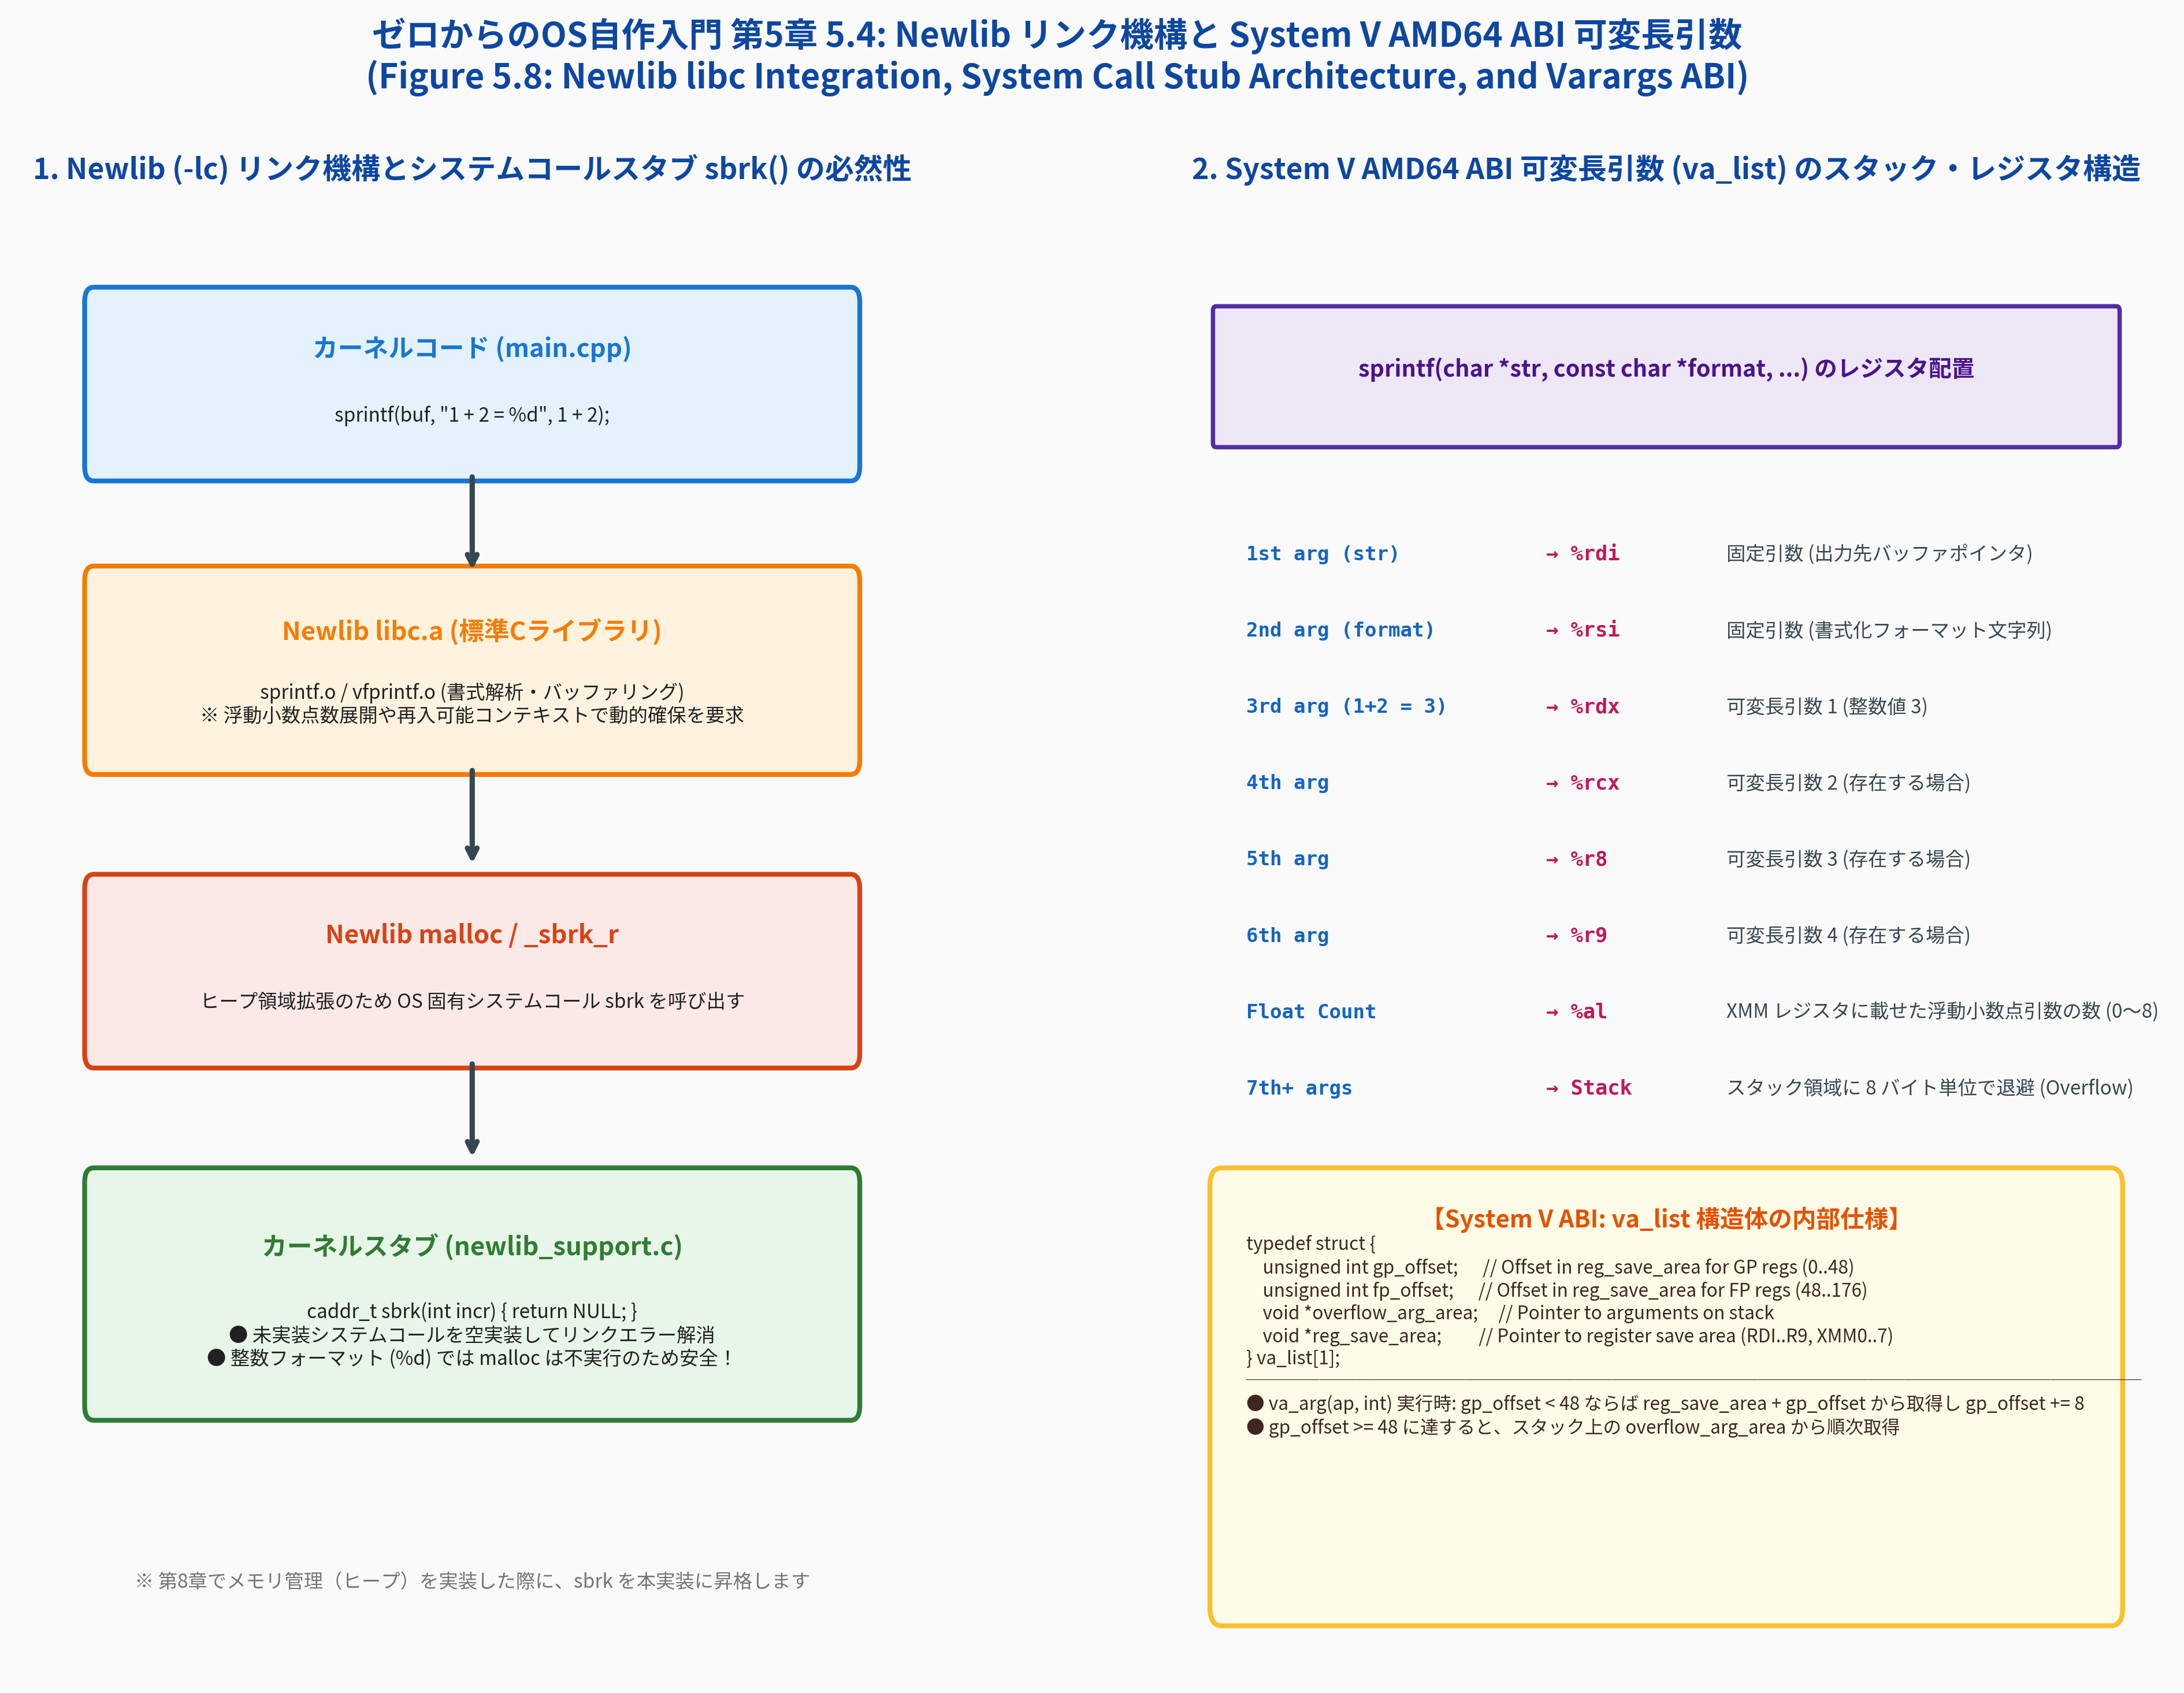

In [6]:
# === Figure 5.8: Newlib リンク機構と System V AMD64 ABI 可変長引数の生成・表示 ===
import os
from common import plot_fig5_08_newlib_sbrk_and_varargs_abi
from IPython.display import Image, display

fig_dir = "result" if os.path.basename(os.getcwd()) == "5" else "5/result"
fig_path = os.path.join(fig_dir, "fig5_08_newlib_sbrk_and_varargs_abi.png")
plot_fig5_08_newlib_sbrk_and_varargs_abi(fig_path)
display(Image(filename=fig_path))


## 7. MikanOS day05d C++20 コアロジックの対話型コンパイル & 画面描画検証

MikanOS の `day05d` カーネルコード（`kernel/main.cpp`, `kernel/font.cpp`, `kernel/newlib_support.c`）のロジックを抽出し、C++20 スタンドアロン検証コード `src/ch05/string_sprintf_sim.cpp` をコンパイル・実行します。

本シミュレータでは以下の処理をベアメタル完全等価で検証します：
1. 仮想フレームバッファ（VRAM 400x120）の確保と `PixelWriter` の生成
2. `WriteString(writer, 0, 66, "Hello, world!", {0, 0, 255})` による青色文字列描画
3. `fake_sbrk(incr)` スタブによるヒープなし安全確認
4. `KernelSprintf(buf, "1 + 2 = %d", 1 + 2)` による文字列フォーマットと `WriteString(writer, 0, 82, buf, {0, 0, 0})` による黒色描画
5. 描画ピクセルオフセット（VRAM 内バイト値）の数学的アサート検証


In [7]:
# === C++20 スタンドアロンシミュレータのコンパイルと実行 ===
import os
import subprocess

cpp_file = "src/ch05/string_sprintf_sim.cpp" if os.path.exists("src/ch05/string_sprintf_sim.cpp") else "../src/ch05/string_sprintf_sim.cpp"
bin_file = "src/ch05/string_sprintf_sim" if os.path.exists("src/ch05") else "../src/ch05/string_sprintf_sim"

# コンパイル (C++20, 最適化 -O2, 警告全有効)
compile_res = subprocess.run(
    ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_file, "-o", bin_file],
    capture_output=True, text=True
)
if compile_res.returncode != 0:
    print("❌ コンパイルエラー:")
    print(compile_res.stderr)
else:
    print("✅ C++20 シミュレータのコンパイルに成功しました。")
    # 実行と検証
    run_res = subprocess.run([bin_file], capture_output=True, text=True)
    print(run_res.stdout)


✅ C++20 シミュレータのコンパイルに成功しました。
 MikanOS Chapter 5.4 C++20 Simulation: String Rendering and sprintf 

[Step 1] Verifying WriteString("Hello, world!", blue) at (0, 66)...
  -> WriteString coordinates and pixel offsets verified successfully!

[Step 2] Verifying sprintf formatting and sbrk stub...
  -> fake_sbrk stub returns NULL correctly without throwing.
  -> KernelSprintf output: "1 + 2 = 3" (length: 9)
[Step 3] Verifying WriteString(buf, black) at (0, 82)...
  -> Formatted string correctly rendered on simulated VRAM.

[Step 4] Advanced sprintf formatting: "VRAM @ 0x00100000, Str: OK"

 [ALL TESTS PASSED] Chapter 5.4 String Rendering and sprintf verified!



## 8. 本節のまとめと次節（5.5節 コンソールクラス）への展望

### 8.1 本節で獲得した中核知識と技術的成果
1. **`WriteString()` による文字列出力の自動化**:
   - 文字列終端記号 `'\0'` までの反復処理と、$x_i = x + 8 \cdot i$ によるピクセル等幅送りにより、任意の文字列を1行の関数呼び出しで画面描画できるようになりました。
2. **Newlib 標準 C ライブラリの統合 (`-lc`)**:
   - ベアメタル Freestanding OS に標準 C ライブラリを静的リンクする機構を学びました。
3. **システムコールスタブ `sbrk()` の必然性**:
   - `sprintf()` の内部実装が要求する動的確保（`malloc`）依存関係を解き明かし、空スタブ（`return NULL;`）によってリンクエラーを安全に解決する手法を習得しました。
4. **System V AMD64 ABI における可変長引数の仕組み**:
   - 汎用レジスタ（RDI〜R9）、浮動小数点レジスタ（XMM0〜7）、`%al` レジスタ、およびスタックフレーム上の `va_list` 構造体のビットレイアウトとメモリモデルを完全に理解しました。

### 8.2 新たな課題：改行処理と画面スクロール
しかし、現在の `WriteString()` にはまだ決定的な制約があります：
- **改行文字 `'\n'` の非対応**: `WriteString("Line 1\nLine 2")` と書いても、`'\n'`（ASCII 0x0A）のフォントグリフがそのまま横に描画され、次の行に移りません。
- **画面端での自動折り返しなし**: 画面の右端（幅 800 ピクセル、100 文字）を超えると、そのまま画面外のメモリ（次行のピクセル）を上書きしてしまいます。
- **画面が満杯になったときのスクロールなし**: 画面下端（高さ 600 ピクセル、37 行）まで文字で埋まった場合、それ以上文字を書く場所がなくなってしまいます。

### 8.3 次節（5.5節 コンソールクラス）への展望
次節 **5.5節「コンソールクラス (`Console`)」** では、これらの課題を根本から解決するため、以下の機能を備えたカーネル内コンソールサブシステムを構築します：
- 25行×80列の文字バッファ管理
- 改行コード `'\n'` に伴うカーソル座標 $(x, y)$ の自動行頭復帰・改行処理
- 最終行（第25行）到達時に画面全体を1行分上にシフトする **「スクロール描画ロジック」** の設計と実装

これにより、UNIX ターミナルのような直感的で本格的な文字出力環境がいよいよ完成します！
